# Treino

Regressão logística: quem vai cancelar o contrato (churn).

In [1]:
import pandas as pd

dataset = pd.read_csv("dados/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("linhas:", len(dataset))
dataset.head(3)

linhas: 7043


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [2]:
# TotalCharges vem como texto e tem células vazias.
# Vira número. As linhas vazias saem.
dataset["TotalCharges"] = pd.to_numeric(dataset["TotalCharges"], errors="coerce")
print("vazias:", dataset["TotalCharges"].isna().sum())
dataset = dataset.dropna(subset=["TotalCharges"])
print("linhas depois:", len(dataset))

vazias: 11
linhas depois: 7032


In [3]:
# O alvo. Churn "Yes" = saiu = 1. "No" = ficou = 0.
y = (dataset["Churn"] == "Yes").astype(int)
print(y.value_counts())
print(y.value_counts(normalize=True).round(3))

Churn
0    5163
1    1869
Name: count, dtype: int64
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64


In [4]:
# Entram 4 colunas: meses de casa, conta do mês, total pago e o tipo de contrato.
from sklearn.model_selection import train_test_split

numericas = ["tenure", "MonthlyCharges", "TotalCharges"]
X = dataset[numericas + ["Contract"]]

# stratify=y: treino e teste ficam com a mesma % de quem sai.
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print("treino:", len(X_treino), "| teste:", len(X_teste))
print("% que sai no treino:", round(y_treino.mean(), 3), "| no teste:", round(y_teste.mean(), 3))

treino: 5274 | teste: 1758
% que sai no treino: 0.266 | no teste: 0.266


In [5]:
# As 3 numéricas ficam na mesma escala. Contract (texto) vira 3 colunas de 0 e 1.
from sklearn.compose import make_column_transformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preparo = make_column_transformer(
    (StandardScaler(), numericas),
    (OneHotEncoder(), ["Contract"]),
    verbose_feature_names_out=False,  # nomes curtos nas colunas
)
modelo = make_pipeline(preparo, LogisticRegression(max_iter=1000))
modelo.fit(X_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['tenure','MonthlyCharges','TotalCharges','Contract']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardscaler', ...), ('onehotencoder', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equiv

In [6]:
# O que o modelo aprendeu. Peso + empurra para "sai". Peso − empurra para "fica".
pesos = pd.Series(modelo[-1].coef_[0], index=modelo[0].get_feature_names_out())
print(pesos.round(2))

tenure                    -1.23
MonthlyCharges             0.73
TotalCharges               0.39
Contract_Month-to-month    0.55
Contract_One year         -0.60
Contract_Two year         -1.30
dtype: float64


In [7]:
# Um cliente do teste (posição 157). O modelo nunca viu este cliente.
cliente = X_teste.iloc[[157]]
print(cliente)

score = modelo.decision_function(cliente)[0]
chance = modelo.predict_proba(cliente)[0, 1]
print("score:", round(score, 2))
print("probabilidade de sair:", round(chance, 2))
print("previsto com limiar 0,5:", modelo.predict(cliente)[0], "| real:", y_teste.iloc[157])

      tenure  MonthlyCharges  TotalCharges        Contract
6462       2           95.65         167.3  Month-to-month
score: 0.95
probabilidade de sair: 0.72
previsto com limiar 0,5: 1 | real: 1


In [8]:
# A sigmoide transforma o score em probabilidade: 1 / (1 + e^(−score)).
import numpy as np

print(round(1 / (1 + np.exp(-score)), 2))

0.72


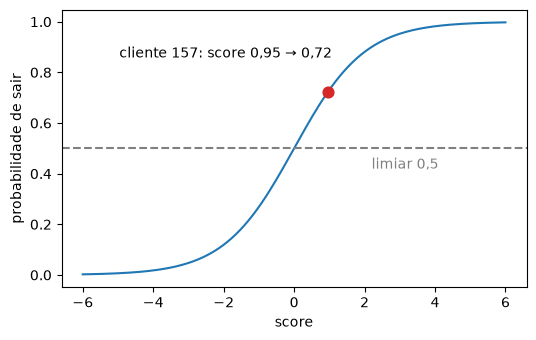

In [9]:
# A curva da sigmoide. O ponto é o cliente 157. A linha tracejada é o limiar 0,5.
import matplotlib.pyplot as plt

z = np.linspace(-6, 6, 200)
plt.figure(figsize=(6, 3.6))
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.axhline(0.5, ls="--", c="gray")
plt.text(2.2, 0.42, "limiar 0,5", color="gray")
plt.scatter([score], [chance], s=60, c="tab:red", zorder=3)
plt.annotate(f"cliente 157: score {score:.2f} → {chance:.2f}".replace(".", ","), (score, chance),
             xytext=(-150, 25), textcoords="offset points")
plt.xlabel("score")
plt.ylabel("probabilidade de sair")
plt.savefig("img/g-sigmoide.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Acurácia: acertos ÷ total, nos clientes do teste.
from sklearn.metrics import accuracy_score

previsto = modelo.predict(X_teste)
print("modelo:", round(accuracy_score(y_teste, previsto), 3))

# O chute: dizer "fica" (0) para todo mundo, sem modelo nenhum.
chute = [0] * len(y_teste)
print("chutar sempre 'fica':", round(accuracy_score(y_teste, chute), 3))

modelo: 0.788
chutar sempre 'fica': 0.734


O chute já acerta 73%, porque a maioria fica. A acurácia sozinha não diz se o modelo acha quem sai. O caderno 02 olha os erros.